# Análise exploratória — readmissão hospitalar em < 30 dias

> ### Resumo executivo
> - **Pergunta:** que características se associam à readmissão em até 30 dias de pacientes diabéticos?
> - **Base:** 99.340 internações elegíveis (69.987 pacientes) de 130 hospitais dos EUA, 1999–2008. Taxa de readmissão: **11,4%**.
> - **Principais achados:**
>   - **Histórico de internações** é o fator mais forte: de 8,6% (nenhuma no ano anterior) para **37,1%** (cinco ou mais).
>   - **Destino da alta:** 9,3% na alta para casa, contra **27,7%** no encaminhamento para reabilitação.
>   - **HbA1c não foi registrada em 83%** das internações; quem fez o exame teve readmissão um pouco menor.
>   - **Diabetes com complicação** (14,7% contra 10,9%) e **ajuste de insulina** marcam pacientes mais complexos.
> - **Da análise à prática:** quatro propostas de protocolo assistencial, com indicadores (seção 8.3).
> - **Cuidado:** associações exploratórias em base histórica — não comprovam causa.

**Pergunta:** quais características da internação e do paciente diabético se associam
à readmissão em menos de 30 dias?

**Dados:** `data-processed/dataset_modelo.csv`, gerado por `etl/pipeline.py`
(99.340 internações elegíveis — óbitos e hospice já removidos).

**Como ler os gráficos:** cada barra é a **taxa de readmissão < 30 dias** naquele grupo.
A linha tracejada é a taxa geral. As barras finas pretas são o intervalo de confiança de 95%
(grupos pequenos têm intervalo largo — não tire conclusões deles).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from etl.rotulos import nome_variavel, rotulo  # nomes em portugues para graficos e tabelas
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAIZ / "data-processed" / "dataset_modelo.csv")
TAXA_GERAL = df["readmit_30"].mean()

# Estilo: uma cor so (a metrica e sempre a mesma), grade discreta.
AZUL, TINTA, TINTA_2, SUPERFICIE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

print(f"Internacoes: {len(df):,} | Pacientes: {df['patient_nbr'].nunique():,}")
print(f"Taxa geral de readmissao < 30 dias: {TAXA_GERAL:.1%}")

Internacoes: 99,340 | Pacientes: 69,987
Taxa geral de readmissao < 30 dias: 11.4%


In [2]:
def taxa_por(coluna, ordem=None, min_n=100):
    """Taxa de readmissao por grupo, com IC 95% de Wilson."""
    g = df.groupby(coluna)["readmit_30"].agg(n="size", eventos="sum")
    g = g[g["n"] >= min_n]
    p = g["eventos"] / g["n"]
    z = 1.96
    centro = (p + z**2 / (2 * g["n"])) / (1 + z**2 / g["n"])
    meia = z * np.sqrt(p * (1 - p) / g["n"] + z**2 / (4 * g["n"] ** 2)) / (1 + z**2 / g["n"])
    g["taxa"], g["ic_inf"], g["ic_sup"] = p, centro - meia, centro + meia
    if ordem is not None:
        g = g.reindex([o for o in ordem if o in g.index])
    return g


def grafico_taxa(tabela, titulo, xlabel="", horizontal=False, arquivo=None):
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(tabela) + 1.8) if horizontal else (8, 4.2), layout="constrained")
    rotulos = [rotulo(i) for i in tabela.index]
    pos = np.arange(len(tabela))
    erro = [tabela["taxa"] - tabela["ic_inf"], tabela["ic_sup"] - tabela["taxa"]]
    if horizontal:
        ax.barh(pos, tabela["taxa"], height=0.6, color=AZUL)
        ax.errorbar(tabela["taxa"], pos, xerr=erro, fmt="none", ecolor=TINTA, elinewidth=1, capsize=0)
        ax.axvline(TAXA_GERAL, color=TINTA_2, linestyle="--", linewidth=1)
        ax.set_yticks(pos, rotulos)
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("Taxa de readmissão < 30 dias")
    else:
        ax.bar(pos, tabela["taxa"], width=0.6, color=AZUL)
        ax.errorbar(pos, tabela["taxa"], yerr=erro, fmt="none", ecolor=TINTA, elinewidth=1, capsize=0)
        ax.axhline(TAXA_GERAL, color=TINTA_2, linestyle="--", linewidth=1)
        ax.set_xticks(pos, rotulos)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.grid(axis="x", visible=False)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Taxa de readmissão < 30 dias")
    # Rotulo so nos extremos (maior e menor taxa) e na linha de referencia.
    for i in {tabela["taxa"].values.argmax(), tabela["taxa"].values.argmin()}:
        v = tabela["taxa"].iloc[i]
        if horizontal:
            ax.annotate(f"{v:.1%}", (tabela["ic_sup"].iloc[i], i), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=10, color=TINTA)
        else:
            ax.annotate(f"{v:.1%}", (i, tabela["ic_sup"].iloc[i]), xytext=(0, 4),
                        textcoords="offset points", ha="center", fontsize=10, color=TINTA)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=13, fontweight="bold")
    ax.set_title(f"Linha tracejada = taxa geral ({TAXA_GERAL:.1%}) · barras pretas = IC 95%",
                 fontsize=9, fontweight="normal", color=TINTA_2, loc="left")
    if arquivo:
        fig.savefig(FIGURAS / arquivo, dpi=150, bbox_inches="tight")
    plt.show()
    return tabela[["n", "taxa"]].style.format({"n": "{:,}", "taxa": "{:.1%}"})

## 1. Visão geral

- Só **~11% das internações** terminam em readmissão < 30 dias → classes **desbalanceadas**.
  Um modelo que sempre diz "não volta" acerta 89% e não serve para nada. Por isso o modelo
  será avaliado por *recall*, ROC-AUC e PR-AUC, não por acurácia.
- Muitos pacientes aparecem mais de uma vez. Isso exige separar treino e teste **por paciente**.

In [3]:
por_paciente = df.groupby("patient_nbr").size()
pd.Series({
    "Internacoes": f"{len(df):,}",
    "Pacientes": f"{len(por_paciente):,}",
    "Pacientes com 2+ internacoes": f"{(por_paciente > 1).sum():,} ({(por_paciente > 1).mean():.0%})",
    "Readmissoes < 30 dias": f"{df['readmit_30'].sum():,} ({TAXA_GERAL:.1%})",
}).to_frame("valor")

,valor
Internacoes,"99,340"
Pacientes,"69,987"
Pacientes com 2+ internacoes,"16,341 (23%)"
Readmissoes < 30 dias,"11,314 (11.4%)"


## 2. Histórico de uso do serviço de saúde

A hipótese clínica: quem já interna com frequência tem doença menos controlada, mais
comorbidades e maior fragilidade — e volta mais.

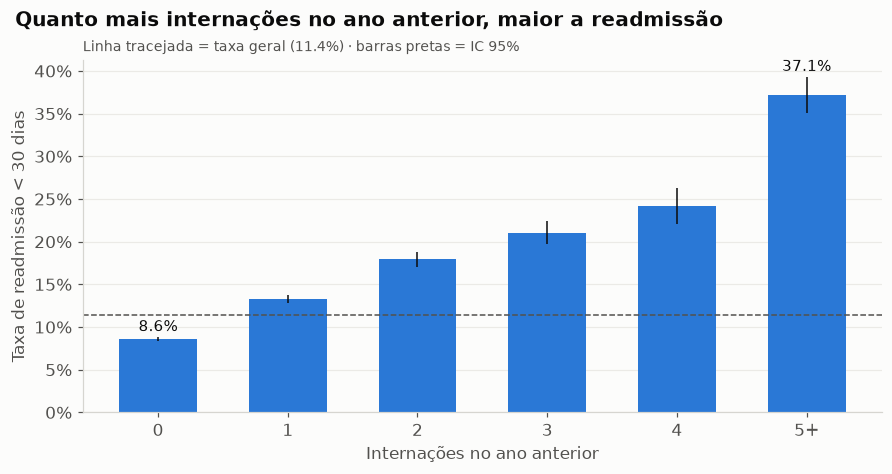

,n,taxa
internacoes_previas,,
0,"66,242",8.6%
1,"18,984",13.3%
2,"7,300",17.9%
3,"3,271",21.0%
4,"1,574",24.1%
5+,"1,969",37.1%


In [4]:
df["internacoes_previas"] = df["number_inpatient"].clip(upper=5).astype(str).replace("5", "5+")
grafico_taxa(
    taxa_por("internacoes_previas", ordem=["0", "1", "2", "3", "4", "5+"]),
    "Quanto mais internações no ano anterior, maior a readmissão",
    xlabel="Internações no ano anterior", arquivo="01_internacoes_previas.png",
)

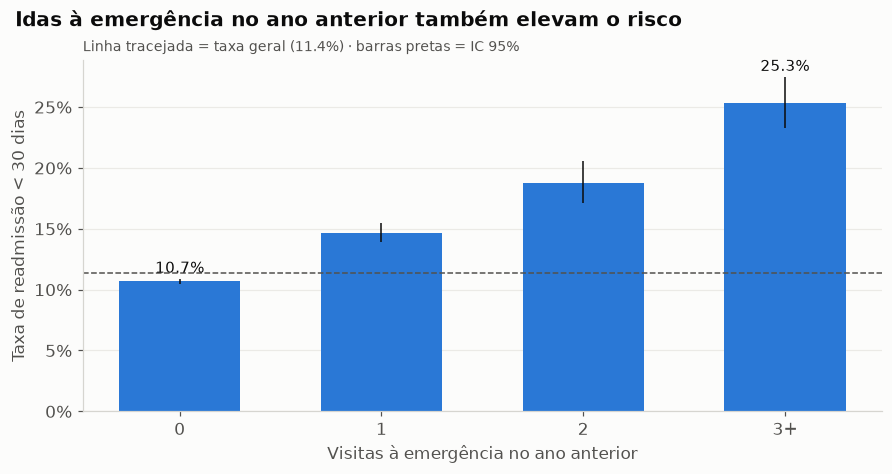

,n,taxa
emergencias_previas,,
0,"88,246",10.7%
1,"7,474",14.7%
2,"1,984",18.8%
3+,"1,636",25.3%


In [5]:
df["emergencias_previas"] = df["number_emergency"].clip(upper=3).astype(str).replace("3", "3+")
grafico_taxa(
    taxa_por("emergencias_previas", ordem=["0", "1", "2", "3+"]),
    "Idas à emergência no ano anterior também elevam o risco",
    xlabel="Visitas à emergência no ano anterior", arquivo="02_emergencias_previas.png",
)

**Leitura:** é o sinal mais forte do dataset. Pacientes com 5+ internações no ano anterior
voltam em < 30 dias cerca de **4 vezes mais** do que quem não teve nenhuma.

## 3. Destino da alta

Para onde o paciente vai depois da alta diz muito sobre a gravidade e a rede de cuidado.

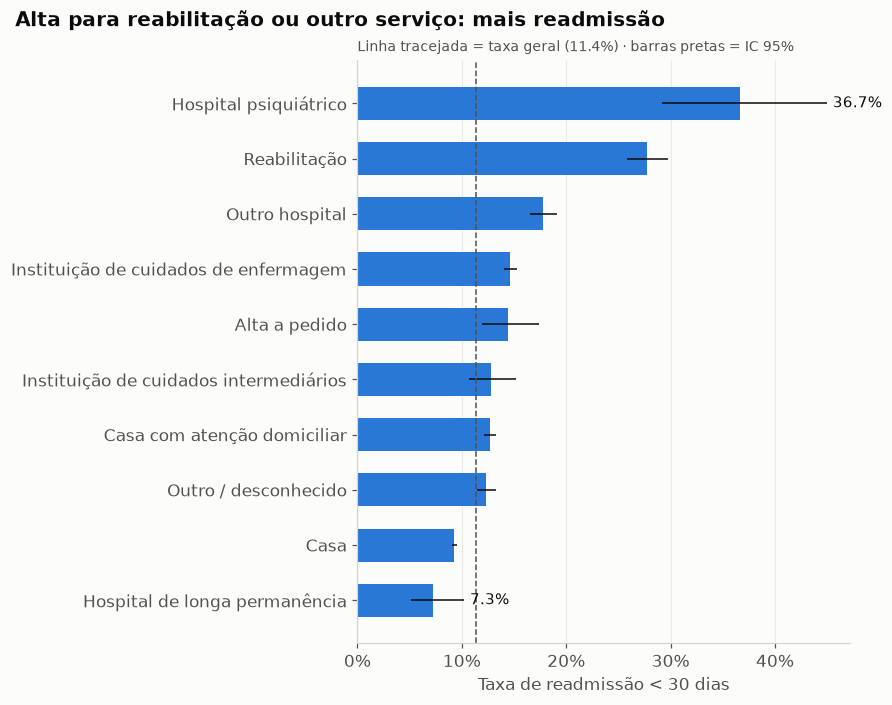

,n,taxa
destino_alta,,
Psiquiatria,139,36.7%
Reabilitacao,"1,992",27.7%
Outro_hospital,"3,312",17.8%
SNF,"13,954",14.7%
Alta_a_pedido,623,14.4%
ICF,815,12.8%
Casa_com_home_care,"13,010",12.7%
Outro_ou_desconhecido,"4,851",12.3%
Casa,"60,232",9.3%


In [6]:
grafico_taxa(
    taxa_por("destino_alta").sort_values("taxa", ascending=False),
    "Alta para reabilitação ou outro serviço: mais readmissão",
    horizontal=True, arquivo="03_destino_alta.png",
)

**Leitura:** alta para casa tem a menor taxa. Transferência para reabilitação, SNF
(*skilled nursing facility*) ou outro hospital indica paciente mais dependente.

## 4. Manejo do diabetes

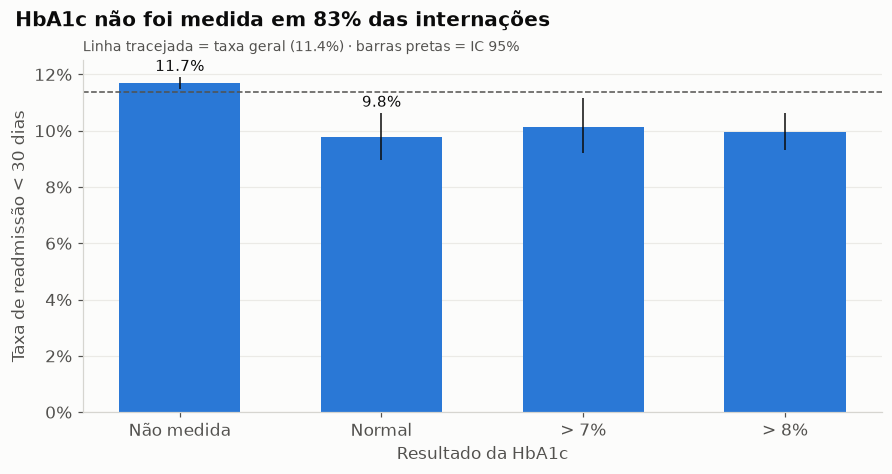

,n,taxa
hba1c,,
Não medida,"82,506",11.7%
Normal,"4,922",9.8%
> 7%,"3,775",10.1%
> 8%,"8,137",9.9%


In [7]:
nomes_hba1c = {"Nao_medido": "Não medida", "Norm": "Normal", ">7": "> 7%", ">8": "> 8%"}
df["hba1c"] = df["A1Cresult"].map(nomes_hba1c)
grafico_taxa(
    taxa_por("hba1c", ordem=["Não medida", "Normal", "> 7%", "> 8%"]),
    "HbA1c não foi medida em 83% das internações",
    xlabel="Resultado da HbA1c", arquivo="04_hba1c.png",
)

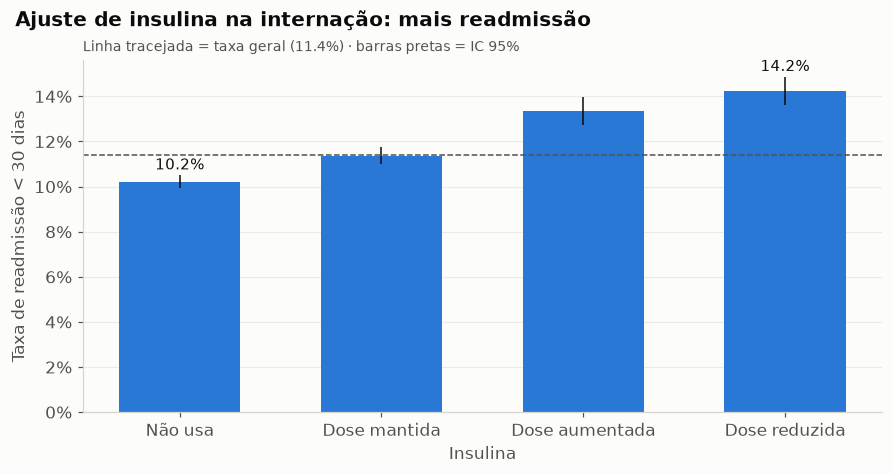

,n,taxa
insulina,,
Não usa,"46,376",10.2%
Dose mantida,"30,069",11.4%
Dose aumentada,"10,987",13.3%
Dose reduzida,"11,908",14.2%


In [8]:
nomes_insulina = {"No": "Não usa", "Steady": "Dose mantida", "Up": "Dose aumentada", "Down": "Dose reduzida"}
df["insulina"] = df["insulin"].map(nomes_insulina)
grafico_taxa(
    taxa_por("insulina", ordem=list(nomes_insulina.values())),
    "Ajuste de insulina na internação: mais readmissão",
    xlabel="Insulina", arquivo="05_insulina.png",
)

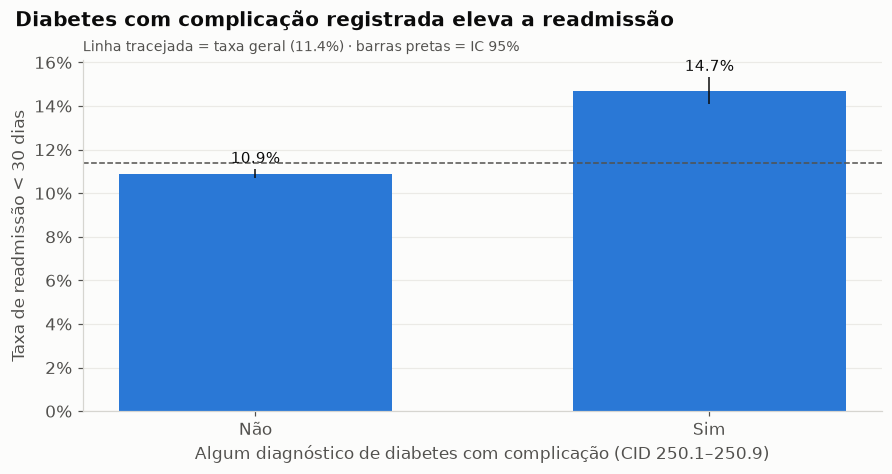

,n,taxa
diabetes_complicacao,,
Não,"86,522",10.9%
Sim,"12,818",14.7%


In [9]:
df["diabetes_complicacao"] = df["diabetes_complicado"].map({0: "Não", 1: "Sim"})
grafico_taxa(
    taxa_por("diabetes_complicacao", ordem=["Não", "Sim"]),
    "Diabetes com complicação registrada eleva a readmissão",
    xlabel="Algum diagnóstico de diabetes com complicação (CID 250.1–250.9)",
    arquivo="06_diabetes_complicado.png",
)

**Leitura:**
- A HbA1c — o principal exame de controle glicêmico — **não foi medida na grande maioria das
  internações**. Quando foi medida, a taxa de readmissão é menor, mesmo com resultado alterado:
  medir provavelmente reflete um cuidado mais atento ao diabetes (é a tese do artigo original,
  Strack et al., 2014).
- Ajustar a insulina (para cima ou para baixo) marca um paciente descompensado.
- Diabetes com complicação registrada (renal, oftalmológica, neurológica, circulatória…)
  aumenta a readmissão.

## 5. Internação e perfil do paciente

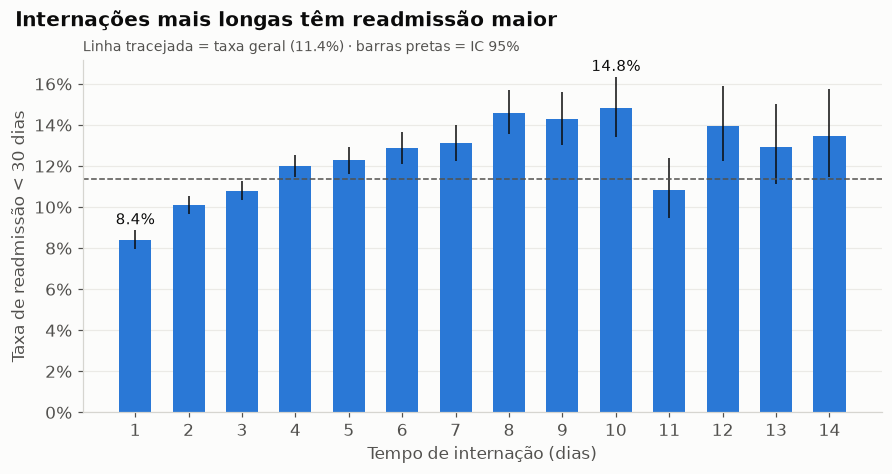

,n,taxa
time_in_hospital,,
1,"13,822",8.4%
2,"16,891",10.1%
3,"17,432",10.8%
4,"13,684",12.0%
5,"9,749",12.3%
6,"7,355",12.9%
7,"5,696",13.1%
8,"4,270",14.6%
9,"2,879",14.3%


In [10]:
grafico_taxa(
    taxa_por("time_in_hospital"),
    "Internações mais longas têm readmissão maior",
    xlabel="Tempo de internação (dias)", arquivo="07_tempo_internacao.png",
)

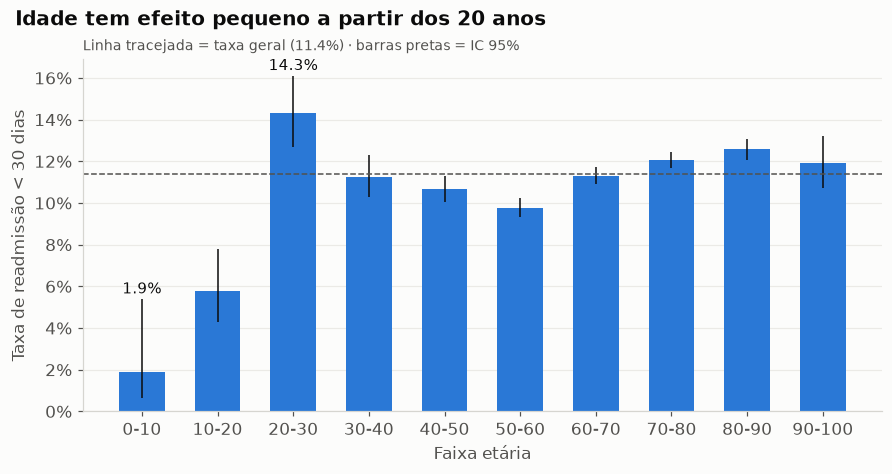

,n,taxa
faixa_etaria,,
0-10,160,1.9%
10-20,690,5.8%
20-30,"1,649",14.3%
30-40,"3,764",11.3%
40-50,"9,607",10.7%
50-60,"17,060",9.8%
60-70,"22,058",11.3%
70-80,"25,329",12.1%
80-90,"16,434",12.6%


In [11]:
faixas = {5: "0-10", 15: "10-20", 25: "20-30", 35: "30-40", 45: "40-50",
          55: "50-60", 65: "60-70", 75: "70-80", 85: "80-90", 95: "90-100"}
df["faixa_etaria"] = df["idade"].map(faixas)
grafico_taxa(
    taxa_por("faixa_etaria", ordem=list(faixas.values())),
    "Idade tem efeito pequeno a partir dos 20 anos",
    xlabel="Faixa etária", arquivo="08_idade.png",
)

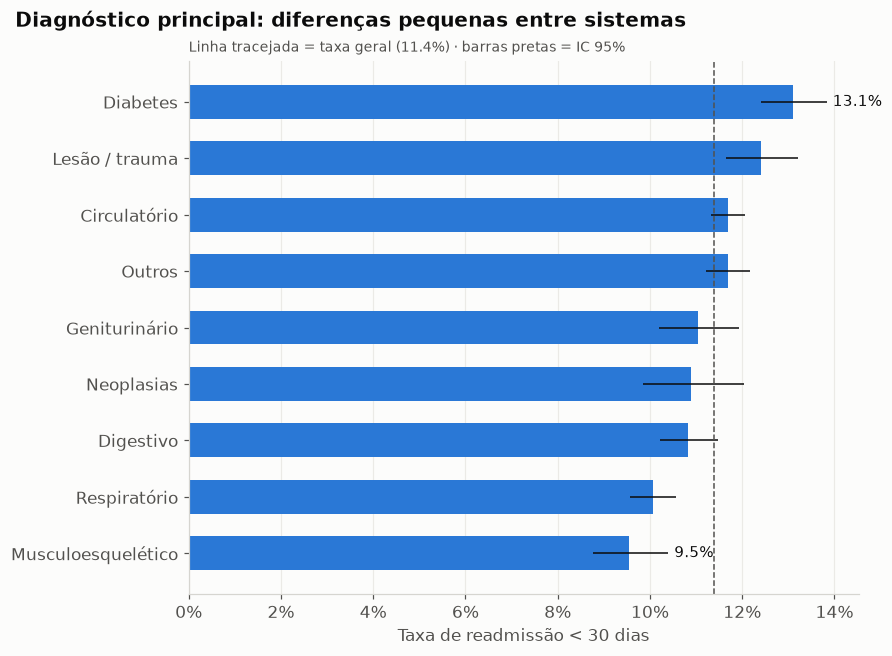

,n,taxa
diag_1_grupo,,
Diabetes,"8,661",13.1%
Lesao_Trauma,"6,851",12.4%
Circulatorio,"29,680",11.7%
Outros,"17,793",11.7%
Geniturinario,"5,002",11.0%
Neoplasias,"3,131",10.9%
Digestivo,"9,333",10.8%
Respiratorio,"13,934",10.1%
Musculoesqueletico,"4,935",9.5%


In [12]:
grafico_taxa(
    taxa_por("diag_1_grupo").sort_values("taxa", ascending=False),
    "Diagnóstico principal: diferenças pequenas entre sistemas",
    horizontal=True, arquivo="09_diagnostico_principal.png",
)

## 6. Variáveis numéricas

Média de cada variável entre quem foi e quem não foi readmitido.

In [13]:
numericas = ["number_inpatient", "number_emergency", "number_outpatient", "total_visitas_previas",
             "time_in_hospital", "num_medications", "num_lab_procedures", "num_procedures",
             "number_diagnoses", "n_medicamentos_diabetes", "n_doses_alteradas", "idade"]
comparacao = df.groupby("readmit_30")[numericas].mean().T
comparacao.columns = ["Não readmitido", "Readmitido < 30d"]
comparacao["Razão"] = comparacao["Readmitido < 30d"] / comparacao["Não readmitido"]
comparacao.index = comparacao.index.map(nome_variavel)
comparacao.sort_values("Razão", ascending=False).style.format("{:.2f}")

,Não readmitido,Readmitido < 30d,Razão
Internações no ano anterior,0.55,1.22,2.20
Idas à emergência no ano anterior,0.18,0.36,2.01
Total de atendimentos no ano anterior,1.09,2.02,1.84
Consultas ambulatoriais no ano anterior,0.36,0.44,1.21
Nº de antidiabéticos com dose alterada,0.28,0.34,1.19
Tempo de internação (dias),4.33,4.77,1.10
Nº de medicamentos na internação,15.86,16.91,1.07
Nº de diagnósticos registrados,7.36,7.69,1.04
Nº de exames laboratoriais,42.74,44.22,1.03
Idade,65.62,66.73,1.02


## 7. Resumo dos achados

| # | Achado | Implicação |
|---|---|---|
| 1 | **Internações e emergências prévias** são o fator mais forte (8,6% → 37% com 5+ internações) | Identificar "usuários frequentes" na admissão |
| 2 | **Destino da alta** importa: reabilitação e transferências voltam mais que alta para casa | Planejamento de alta e transição de cuidado |
| 3 | **HbA1c não é medida em 83% das internações**, e quem mede tem readmissão menor | Oportunidade simples de protocolo |
| 4 | **Ajuste de insulina** e **diabetes com complicação** marcam paciente descompensado | Reforçar educação em saúde na alta |
| 5 | Idade, diagnóstico principal e tipo de admissão têm efeito **pequeno** | Não devem ser o foco de uma intervenção |
| 6 | Classe desbalanceada (11%) e pacientes repetidos | Métricas certas e split por paciente no modelo |

A interpretação clínica de cada achado e as propostas de prevenção estão na seção 8.

# 8. Discussão clínica e oportunidades de prevenção

## 8.1. Contexto e cuidados na interpretação

A análise exploratória identificou características associadas à readmissão hospitalar em até 30 dias: o histórico de internações, o destino da alta, a realização de exames de controle glicêmico e a complexidade clínica do diabetes.

Os achados foram interpretados a partir de duas perspectivas — a analítica e a da prática de enfermagem —, com foco na identificação precoce de pacientes que utilizam mais os serviços de saúde, no monitoramento de condições crônicas, na educação em saúde e na continuidade do cuidado após a alta.

Dois cuidados orientam toda a leitura desta seção:

- **Associação não é causalidade.** Os padrões observados indicam quem tem maior chance de retornar, mas não explicam por quê. As intervenções propostas são **oportunidades de prevenção a serem avaliadas**, e não medidas com efetividade comprovada por este projeto.
- **A base é histórica** (hospitais dos EUA, 1999–2008) e não representa necessariamente os processos assistenciais atuais nem a realidade dos hospitais brasileiros. Ela serve para explorar padrões e formular hipóteses.

## 8.2. Interpretação clínica dos principais achados

### 8.2.1. Histórico de internações e atendimentos de emergência

**Achado:** a proporção de readmissões aumentou de **8,6%**, entre pacientes sem internações no ano anterior, para **37,1%** entre aqueles com cinco ou mais. O mesmo gradiente aparece nos atendimentos de emergência (de 10,7% para 25,3% com três ou mais). Foi o fator mais forte da análise exploratória.

**Interpretação:** o resultado reforça a importância de considerar o histórico assistencial do paciente já na admissão, e não apenas a condição clínica que motivou a internação atual. Internações recorrentes podem refletir doenças crônicas descompensadas, dificuldades de adesão ao tratamento, limitações funcionais ou barreiras de acesso aos serviços de saúde — hipóteses que o número de internações, sozinho, não confirma. Por isso, o histórico deve **disparar uma avaliação individualizada**, e não classificar automaticamente o paciente como de alto risco.

**Oportunidades de melhoria:**

- Construir um perfil longitudinal do paciente, reunindo internações e atendimentos de emergência anteriores, diagnósticos, procedimentos e destinos de alta.
- Avaliar a criação de um alerta assistencial a partir da segunda internação, para revisão do histórico e identificação de necessidades adicionais de cuidado.
- Encaminhar pacientes com três ou mais internações no período para avaliação multiprofissional.
- Investigar padrões recorrentes de descompensação, dificuldades com o tratamento e falhas na continuidade da assistência.

Esses indicadores de utilização hospitalar já foram incluídos no modelo preditivo (`02_modelo.ipynb`) e estão entre as variáveis de maior peso.

### 8.2.2. Destino da alta hospitalar

**Achado:** pacientes que receberam alta para casa tiveram a menor taxa de readmissão (**9,3%**). As taxas foram maiores entre os encaminhados para reabilitação (**27,7%**), transferidos para outro hospital (**17,8%**) ou para instituições de cuidados de enfermagem (**14,7%**).

**Interpretação:** o destino da alta tende a refletir a complexidade clínica, o grau de dependência e a necessidade de cuidados continuados. Assim, a associação **não significa que a reabilitação ou a transferência aumentem o risco** — esses destinos provavelmente identificam pacientes que já eram mais complexos.

Isso torna a transição do cuidado um ponto central de prevenção. A Política Nacional de Atenção Hospitalar (PNHOSP) define a **alta hospitalar responsável** como transferência do cuidado, realizada por meio da orientação de pacientes e familiares para a continuidade do tratamento e o autocuidado, da articulação com os demais pontos da Rede de Atenção à Saúde — em especial a Atenção Básica — e de mecanismos de desospitalização [1, 2].

**Oportunidades de melhoria:**

- Iniciar o planejamento da alta desde a admissão.
- Avaliar as necessidades clínicas, funcionais e sociais do paciente antes da alta.
- Garantir a comunicação entre o hospital e o serviço que dará continuidade ao cuidado.
- Investigar os motivos das readmissões por destino da alta, diferenciando retornos ligados à condição clínica inicial daqueles associados a falhas na transição do cuidado.

### 8.2.3. Realização de HbA1c e acompanhamento glicêmico

**Achado:** a HbA1c **não foi registrada em 83% das internações**. Quando o exame foi realizado, a taxa de readmissão foi um pouco menor (9,8% a 10,1%, contra 11,7% sem o exame) — inclusive entre pacientes com resultado alterado. O artigo que originou esta base chegou a uma conclusão semelhante [7].

**Interpretação:** a hemoglobina glicada estima o controle glicêmico dos meses anteriores à internação. A ausência do registro, porém, não significa necessariamente que o paciente ficou sem acompanhamento glicêmico: ela pode refletir a indicação clínica, a disponibilidade do exame, a existência de resultado recente ou a forma como os dados foram coletados. A hipótese mais plausível é que **realizar o exame seja um marcador de cuidado mais atento ao diabetes**, e não que o exame, isoladamente, reduza as readmissões.

**Fundamentação clínica:** a diretriz da Sociedade Brasileira de Diabetes (SBD) para o manejo da hiperglicemia hospitalar recomenda rastrear a hiperglicemia na admissão de todos os pacientes adultos, independentemente do diagnóstico prévio de diabetes, e solicitar HbA1c para pacientes com diabetes ou hiperglicemia hospitalar confirmada quando não houver resultado nos últimos três meses [3]. A American Diabetes Association traz recomendação semelhante [5].

**Oportunidades de melhoria:**

- Avaliar a adesão institucional ao rastreamento glicêmico na admissão.
- Avaliar a solicitação de HbA1c em pacientes com diabetes ou hiperglicemia, considerando a existência de exame recente.
- Investigar a completude dos registros de glicemia capilar e plasmática.
- Verificar se a ausência de HbA1c se concentra em perfis clínicos ou unidades assistenciais específicas.

### 8.2.4. Diabetes com complicações e ajuste da insulinoterapia

**Achado:** pacientes com diabetes com complicação registrada (CID-9 250.1 a 250.9) tiveram **14,7%** de readmissão, contra **10,9%** dos demais. Pacientes com dose de insulina reduzida ou aumentada durante a internação tiveram 14,2% e 13,3%, contra 10,2% entre os que não usavam insulina.

**Interpretação:** esses achados sugerem que pacientes com manejo mais complexo do diabetes precisam de acompanhamento mais próximo durante a internação e após a alta. A insulinoterapia exige atenção à dose, aos horários, à alimentação, ao monitoramento glicêmico e ao reconhecimento de hipoglicemia e hiperglicemia — e uma mudança de esquema perto da alta exige que o paciente aprenda um novo regime em pouco tempo. Na perspectiva da enfermagem, a segurança na administração de insulina e a educação em saúde são componentes centrais desse cuidado.

A SBD recomenda que as instituições adotem protocolos de controle glicêmico hospitalar e um planejamento de alta iniciado precocemente, com reconciliação medicamentosa, educação em diabetes e orientação para o acompanhamento ambulatorial [4].

**Oportunidades de melhoria:**

- Avaliar a adequação do monitoramento glicêmico durante a internação e registrar episódios de hipoglicemia e hiperglicemia.
- Reforçar a segurança na administração de insulina (prescrição, dose, horário e condição clínica).
- Avaliar a compreensão do paciente e do cuidador sobre o tratamento antes da alta.
- Investigar dificuldades de acesso a medicamentos e insumos necessários para continuar o tratamento em casa.

### 8.2.5. Idade, diagnóstico principal e tipo de admissão

**Achado:** essas variáveis mostraram diferenças pequenas nas taxas de readmissão (por exemplo, entre 10% e 13% nas faixas etárias acima de 20 anos) e menor contribuição individual do que o histórico de utilização hospitalar.

**Interpretação:** isso não significa que sejam clinicamente irrelevantes. A readmissão tende a resultar de uma **combinação** de fatores clínicos, funcionais, sociais e assistenciais, muitos dos quais não estão na base. A idade, por exemplo, pode ganhar relevância quando combinada com dependência funcional, multimorbidade ou falta de suporte familiar.

**Oportunidades de melhoria:** em análises futuras, incluir comorbidades, indicadores de dependência funcional, suporte familiar e condições sociais, e investigar interações entre idade, comorbidades e histórico de internações.

### 8.2.6. Implicações para o modelo preditivo

Dois achados exigem cuidado metodológico na construção do modelo:

- **Desbalanceamento:** apenas cerca de 11% das internações terminam em readmissão. Um modelo pode ter acurácia alta simplesmente prevendo que ninguém será readmitido — por isso, a avaliação deve usar métricas como sensibilidade (*recall*), precisão e PR-AUC.
- **Pacientes repetidos:** 16.341 pacientes aparecem em mais de uma internação. Se registros do mesmo paciente caírem no treino e no teste, o modelo pode "reconhecer" o paciente e o desempenho fica superestimado.

Ambos foram tratados no notebook `02_modelo.ipynb`: a divisão entre treino e teste foi feita **por paciente**, os modelos usam pesos balanceados e a avaliação usa ROC-AUC, PR-AUC, sensibilidade e precisão.

## 8.3. Propostas de protocolos assistenciais

As propostas a seguir foram elaboradas a partir dos achados exploratórios e de recomendações clínicas e institucionais. São **sugestões para discussão**: sua adoção depende de avaliação multiprofissional, adaptação à realidade do serviço e validação da efetividade.

### 8.3.1. Identificação e acompanhamento de pacientes com internações recorrentes

**Objetivo:** identificar pacientes que utilizam os serviços hospitalares com frequência e direcionar uma avaliação individualizada.
**Justificativa:** o histórico de internações e de atendimentos de emergência foi o fator mais associado à readmissão (seção 8.2.1).

**Intervenção proposta:**

1. Identificar, na admissão, pacientes com internações anteriores.
2. Revisar o histórico de utilização dos serviços de saúde e os motivos das internações anteriores.
3. Identificar condições clínicas recorrentes e possíveis dificuldades com o tratamento.
4. Avaliar a necessidade de acompanhamento multiprofissional.
5. Registrar as necessidades identificadas no plano de cuidados e definir o acompanhamento após a alta.

Sugere-se considerar a revisão do histórico a partir da segunda internação. Os critérios para definir um paciente como "recorrente" devem considerar a população atendida e os recursos disponíveis.

**Indicadores sugeridos:** proporção de pacientes com histórico de internação identificado na admissão; proporção de pacientes recorrentes com avaliação multiprofissional; número de internações por paciente no período; taxa de readmissão entre pacientes recorrentes.

### 8.3.2. Rastreamento e monitoramento glicêmico hospitalar

**Objetivo:** melhorar a identificação e o acompanhamento de pacientes com diabetes ou hiperglicemia durante a internação.
**Justificativa:** a ausência de HbA1c em 83% das internações indica uma oportunidade de revisar os processos de avaliação glicêmica (seção 8.2.3).
**Fundamentação:** diretrizes da SBD [3, 4] e da ADA [5].

**Intervenção proposta:**

1. Realizar glicemia na admissão de pacientes adultos, conforme protocolo institucional.
2. Identificar pacientes com diabetes previamente diagnosticado ou com hiperglicemia hospitalar.
3. Avaliar a indicação de HbA1c, considerando a existência de resultado nos últimos três meses.
4. Definir o monitoramento glicêmico conforme a condição clínica e registrar episódios de hipoglicemia e hiperglicemia.
5. Sinalizar à equipe médica a necessidade de ajuste terapêutico.
6. Incorporar as informações glicêmicas ao planejamento da alta.

**Indicadores sugeridos:** proporção de adultos com glicemia registrada na admissão; proporção de pacientes com diabetes ou hiperglicemia com HbA1c recente ou indicação avaliada; frequência de episódios de hipoglicemia e hiperglicemia; proporção de pacientes com plano de acompanhamento glicêmico documentado na alta.

### 8.3.3. Alta segura e educação em saúde para pacientes com diabetes

**Objetivo:** preparar o paciente e a família para continuar o tratamento com segurança após a alta.
**Justificativa:** complicações do diabetes e ajustes de insulina se associaram a mais readmissões (seção 8.2.4).
**Fundamentação:** a SBD recomenda planejamento precoce da alta, reconciliação medicamentosa, educação em diabetes e orientação para acompanhamento ambulatorial [4]; a PNHOSP prevê orientação ao paciente e à família e incentivo ao autocuidado [1, 2].

**Intervenção proposta:**

1. Iniciar o planejamento da alta durante a internação e avaliar a capacidade de autocuidado.
2. Realizar a reconciliação medicamentosa.
3. Orientar sobre a administração de insulina e demais medicamentos, alimentação e monitoramento glicêmico.
4. Ensinar a reconhecer sinais de hipoglicemia e hiperglicemia e quando procurar atendimento.
5. Avaliar a compreensão do paciente e do cuidador (por exemplo, pedindo que expliquem ou demonstrem o que aprenderam).
6. Registrar as orientações e definir o acompanhamento ambulatorial.

A educação deve ser individualizada conforme o nível de compreensão, as condições clínicas e o suporte familiar disponível.

**Indicadores sugeridos:** proporção de pacientes com diabetes com orientação de alta documentada; proporção com reconciliação medicamentosa; proporção com retorno ambulatorial definido; frequência de retornos relacionados a dificuldades no manejo do diabetes.

### 8.3.4. Transição do cuidado após a alta

**Objetivo:** fortalecer a continuidade assistencial entre o hospital e os serviços que acompanharão o paciente.
**Justificativa:** o destino da alta se associou à readmissão, indicando pacientes que dependem de uma transição bem coordenada (seção 8.2.2).
**Fundamentação:** a alta hospitalar responsável da PNHOSP [1, 2]. A Linha de Cuidado do Ministério da Saúde para DM2, por exemplo, orienta reavaliação na Atenção Primária em até 15 dias após cetoacidose diabética e em até 30 dias após estado hiperglicêmico hiperosmolar [6].

**Intervenção proposta:**

1. Elaborar um plano de alta individualizado, com as necessidades de acompanhamento identificadas.
2. Encaminhar para a Atenção Básica ou serviço especializado, com registro das informações clínicas e do tratamento.
3. Orientar o paciente e a família sobre sinais de alerta.
4. Avaliar contato telefônico após a alta para pacientes selecionados, conforme recursos e critérios de elegibilidade definidos pela instituição.
5. Investigar dificuldades de acesso ao acompanhamento e aos medicamentos.

**Indicadores sugeridos:** proporção de pacientes com plano de alta e encaminhamento documentados; proporção com acompanhamento ambulatorial agendado; taxa de readmissão em 30 dias; frequência de retornos relacionados a falhas na continuidade do tratamento.

## 8.4. Evolução da base de dados

A base já traz um identificador do paciente e a contagem de internações, atendimentos de emergência e consultas ambulatoriais no ano anterior. Para estudos futuros, seria importante incorporar:

- **Datas de admissão e alta**, que permitiriam calcular o intervalo entre internações e fazer validação temporal do modelo.
- **Motivo da readmissão**, para distinguir retornos evitáveis daqueles não relacionados à internação anterior.
- **Comorbidades estruturadas** (a base registra apenas três diagnósticos por internação).
- **Indicadores de dependência funcional** e de **condições sociais e suporte familiar**.
- **Registros pós-alta:** encaminhamentos, consultas de retorno, contato com a Atenção Básica e adesão ao tratamento.
- **Peso e dados antropométricos**, hoje ausentes em 97% das internações.

Também será importante avaliar a completude dos registros, comparando pacientes com e sem informações documentadas. Qualquer nova variável deve estar disponível **no momento em que o modelo seria usado**, para não depender de informações que só existem depois da alta.

## 8.5. Limitações

- Por ser uma base histórica de hospitais dos EUA, os padrões podem não refletir as práticas atuais, os protocolos vigentes ou a população atendida em hospitais brasileiros.
- Variáveis clínicas, funcionais e sociais importantes não estão disponíveis.
- A associação entre HbA1c e readmissão pode refletir diferenças no acompanhamento, na complexidade clínica ou na qualidade dos registros.
- A associação entre destino da alta e readmissão pode refletir a condição clínica dos pacientes, e não a qualidade do processo de alta.

Por isso, os achados são **evidências exploratórias** para orientar investigações e propostas de melhoria — não comprovação de que as intervenções reduzirão as readmissões.

## 8.6. Considerações finais

A análise mostrou que o **histórico de utilização dos serviços de saúde**, o **destino da alta** e o **acompanhamento do diabetes** estão entre as características mais associadas à readmissão. A partir deles, foram propostas oportunidades de melhoria na identificação de pacientes recorrentes, no monitoramento glicêmico, na educação em saúde, no planejamento da alta e na continuidade do cuidado.

A integração entre análise de dados e conhecimento clínico permite transformar padrões estatísticos em hipóteses e propostas de intervenção, mantendo a segurança do paciente e a individualização da assistência como princípios. O próximo notebook (`02_modelo.ipynb`) usa esses fatores para construir um escore de risco e discute como ele poderia apoiar a priorização assistencial.

# 9. Referências

1. BRASIL. Ministério da Saúde. **Portaria nº 3.390, de 30 de dezembro de 2013.** Institui a Política Nacional de Atenção Hospitalar (PNHOSP) no âmbito do Sistema Único de Saúde (SUS). Art. 16. Disponível em: https://bvs.saude.gov.br/bvs/saudelegis/gm/2013/prt3390_30_12_2013.html.
2. BRASIL. Ministério da Saúde. **Portaria de Consolidação nº 2, de 28 de setembro de 2017.** Consolidação das normas sobre as políticas nacionais de saúde do SUS. Anexo XXIV (PNHOSP), art. 17. Disponível em: https://portalsinan.saude.gov.br/images/documentos/Legislacoes/Portaria_Consolidacao_2_28_SETEMBRO_2017.pdf.
3. MARINO, E. C. et al. **Manejo da hiperglicemia hospitalar em pacientes não críticos.** Diretriz Oficial da Sociedade Brasileira de Diabetes, 2025. DOI: 10.29327/5660187.2025-9. Disponível em: https://diretriz.diabetes.org.br/manejo-da-hiperglicemia-hospitalar-em-pacientes-nao-criticos/.
4. MOMESSO, D. et al. **Diretrizes clínicas para implantação de programa de controle glicêmico hospitalar (PCGH).** Diretriz Oficial da Sociedade Brasileira de Diabetes, 2025. DOI: 10.29327/5660187.2025-1. Disponível em: https://diretriz.diabetes.org.br/diretrizes-clinicas-para-implantacao-de-programa-de-controle-glicemico-hospitalar-pcgh/.
5. AMERICAN DIABETES ASSOCIATION PROFESSIONAL PRACTICE COMMITTEE. 16. Diabetes Care in the Hospital: Standards of Care in Diabetes—2026. **Diabetes Care**, v. 49, supl. 1, 2026. Disponível em: https://diabetesjournals.org/care/article/49/Supplement_1/S339/163925/16-Diabetes-Care-in-the-Hospital-Standards-of-Care.
6. BRASIL. Ministério da Saúde. **Linhas de Cuidado: Diabetes Mellitus tipo 2 (DM2) no adulto — Unidade Hospitalar: Hiperglicemia aguda sintomática.** Disponível em: https://linhasdecuidado.saude.gov.br/portal/diabetes-mellitus-tipo-2-%28DM2%29-no-adulto/unidade-hospitalar/dm2-aguda/hiperglicemia/sintomatica/.
7. STRACK, B. et al. Impact of HbA1c measurement on hospital readmission rates: analysis of 70,000 clinical database patient records. **BioMed Research International**, v. 2014, art. 781670, 2014. DOI: 10.1155/2014/781670.
8. CLORE, J.; CIOS, K.; DESHAZO, J.; STRACK, B. **Diabetes 130-US Hospitals for Years 1999-2008** [conjunto de dados]. UCI Machine Learning Repository, 2014. DOI: 10.24432/C5230J.

> **Nota:** as propostas de protocolos apresentadas neste projeto são recomendações para discussão e desenvolvimento institucional. Não substituem protocolos clínicos vigentes, avaliação multiprofissional ou decisões individualizadas de assistência.